## Explainability (RQ3)

Which questions drive the predictions, and do SHAP, LIME and the EBM's own importances agree? All three explain the same model: an EBM trained on 80% of each age group (with `interactions=0`, so it is purely additive) and explained on the remaining 20%.

Since the label is the sum of the answers, every question has equal weight under the true rule. Differences in importance reflect how answers are spread in this sample, not clinical importance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from interpret.glassbox import ExplainableBoostingClassifier
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split

PROCESSED = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")

SEED = 42
GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
FEATURES = QUESTIONS + ["age", "male", "jaundice", "family_asd"]
CATEGORICAL = [i for i, f in enumerate(FEATURES) if f != "age"]

COLUMN, PAGE = 3.5, 7.16  # IEEE widths in inches
sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})
FEATURE_NAMES = {"age": "Age", "male": "Male", "jaundice": "Jaundice", "family_asd": "Family ASD"}

### 1. Three ways of measuring importance

In [2]:
def ebm_importance(model):
    ebm = model.named_steps["clf"]
    return pd.Series(ebm.term_importances(), index=ebm.term_names_)


def shap_explanation(model, X_train, X_test):
    predict = lambda d: model.predict_proba(pd.DataFrame(d, columns=FEATURES))[:, 1]
    explainer = shap.Explainer(predict, shap.sample(X_train, 50, random_state=SEED), seed=SEED)
    return explainer(X_test)


def lime_importance(model, X_train, X_test):
    explainer = LimeTabularExplainer(X_train.to_numpy(float), feature_names=FEATURES,
                                     categorical_features=CATEGORICAL, random_state=SEED)
    predict = lambda d: model.predict_proba(pd.DataFrame(d, columns=FEATURES))
    total = np.zeros(len(FEATURES))
    for row in X_test.to_numpy(float):
        exp = explainer.explain_instance(row, predict, num_features=len(FEATURES))
        for i, w in exp.as_map()[1]:
            total[i] += abs(w)
    return pd.Series(total / len(X_test), index=FEATURES)

In [3]:
importance, shap_values = {}, {}

for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    X_train, X_test, y_train, y_test = train_test_split(
        df[FEATURES], df["asd"], test_size=0.2, stratify=df["asd"], random_state=SEED)

    model = Pipeline([
        ("smote", SMOTENC(categorical_features=CATEGORICAL, random_state=SEED)),
        ("clf", ExplainableBoostingClassifier(interactions=0, random_state=SEED)),
    ]).fit(X_train, y_train)
    print(f"{g:<11} test accuracy {model.score(X_test, y_test):.3f}")

    sv = shap_explanation(model, X_train, X_test)
    shap_values[g] = sv
    importance[g] = pd.DataFrame({
        "EBM": ebm_importance(model),
        "SHAP": pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES),
        "LIME": lime_importance(model, X_train, X_test),
    })

toddler     test accuracy 1.000


child       test accuracy 1.000


adolescent  test accuracy 1.000


adult       test accuracy 1.000


### 2. Importance per method and age group

Each column is scaled to sum to 1 so the three methods can be shown side by side.

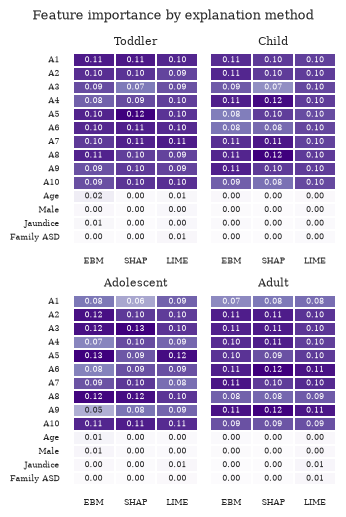

In [4]:
scaled = pd.concat({g: imp / imp.sum() for g, imp in importance.items()}, axis=1)
scaled.to_csv(TABLES / "feature_importance.csv")

fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 5.2), sharey=True)
for ax, g in zip(axes.flat, GROUPS):
    sns.heatmap(scaled[g].rename(index=FEATURE_NAMES), annot=True, fmt=".2f", annot_kws={"size": 5.5},
                cmap="Purples", cbar=False, linewidths=0.3, ax=ax)
    ax.set_title(g.capitalize())
    ax.tick_params(axis="y", rotation=0, labelsize=6)
    ax.tick_params(axis="x", labelsize=6)
fig.suptitle("Feature importance by explanation method")
fig.tight_layout()
fig.savefig(FIGURES / "fig_importance_by_method.png")

### 3. Do the methods agree?

Two measures per pair of methods:

* **Spearman's ρ** between the rankings of the ten questions
* **Top-5 overlap**: how many of the five most important questions are shared (out of 5)

Only A1–A10 are ranked. The four personal details are near zero under every method, so including them would make the agreement look better than it is.

In [5]:
rows = []
for g, imp in importance.items():
    imp = imp.loc[QUESTIONS]
    for a, b in [("EBM", "SHAP"), ("EBM", "LIME"), ("SHAP", "LIME")]:
        top_a, top_b = set(imp[a].nlargest(5).index), set(imp[b].nlargest(5).index)
        rows.append({"group": g, "pair": f"{a} vs {b}",
                     "spearman": imp[a].corr(imp[b], method="spearman"),
                     "top-5 overlap": len(top_a & top_b)})

agreement = pd.DataFrame(rows)
agreement.to_csv(TABLES / "explanation_agreement.csv", index=False)
agreement.pivot(index="group", columns="pair", values=["spearman", "top-5 overlap"]).loc[GROUPS].round(2)

spearman                          top-5 overlap              \
pair       EBM vs LIME EBM vs SHAP SHAP vs LIME   EBM vs LIME EBM vs SHAP   
group                                                                       
toddler           0.22        0.61         0.67           3.0         4.0   
child             0.95        0.71         0.78           5.0         4.0   
adolescent        0.77        0.45         0.30           5.0         4.0   
adult             0.92        0.81         0.89           5.0         4.0   

                         
pair       SHAP vs LIME  
group                    
toddler             4.0  
child               4.0  
adolescent          4.0  
adult               4.0

### 4. Top questions per age group

In [6]:
top = pd.DataFrame({
    (g, m): importance[g][m].loc[QUESTIONS].nlargest(5).index.tolist()
    for g in GROUPS for m in ["EBM", "SHAP", "LIME"]
}, index=[f"#{i}" for i in range(1, 6)])
top

toddler           child           adolescent           adult          
       EBM SHAP LIME   EBM SHAP LIME        EBM SHAP LIME   EBM SHAP LIME
#1      A1   A5   A7    A4   A8   A8         A5   A3   A5    A9   A6   A6
#2      A8   A1   A1    A9   A4   A4         A8   A8  A10    A7   A9   A9
#3      A5   A6   A6    A8   A7   A9         A2  A10   A8    A2   A3   A7
#4      A6   A7  A10    A2   A1   A2         A3   A7   A3    A6   A2   A2
#5      A2   A2   A5    A1   A9   A1        A10   A2   A2    A3   A4   A3

Comparing the same item number across groups needs care. Q-CHAT-10 and the three AQ-10 versions ask different questions under the same label (see `app/questions.py`), so "A9 matters for adults and children" may mean two different questions.

### 5. SHAP summary plots

Each dot is one person in the test set. Red dots are answers scored 1 (towards autistic traits); points to the right push the prediction towards "ASD traits".

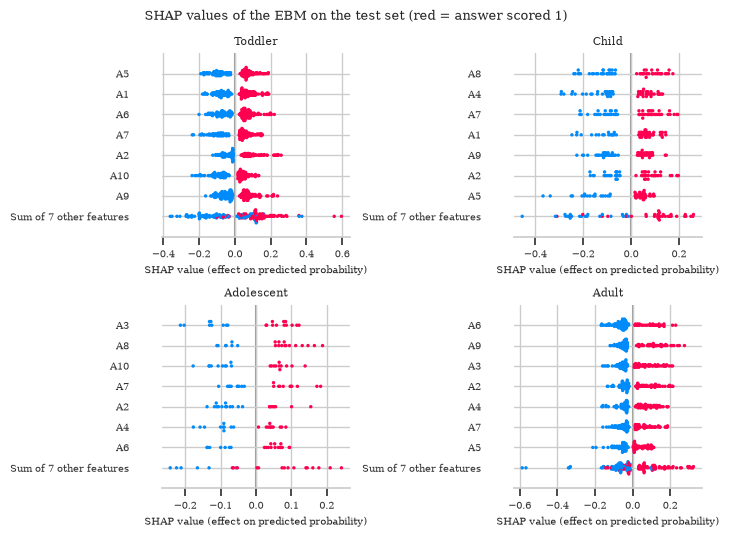

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(PAGE, 5.4))
for ax, g in zip(axes.flat, GROUPS):
    sv = shap_values[g]
    sv.feature_names = [FEATURE_NAMES.get(f, f) for f in FEATURES]
    shap.plots.beeswarm(sv, max_display=8, show=False, ax=ax, plot_size=None, color_bar=False, s=6)
    ax.set_title(g.capitalize())
    ax.set_xlabel("SHAP value (effect on predicted probability)", fontsize=7)
    ax.tick_params(labelsize=7)
fig.suptitle("SHAP values of the EBM on the test set (red = answer scored 1)")
fig.tight_layout()
fig.savefig(FIGURES / "fig_shap_beeswarm.png")

### 6. Answer to RQ3

* **All ten questions matter about equally.** In every group and under every method, each question receives roughly 0.07–0.13 of the total importance, close to the 0.10 that the equal-weight scoring rule implies. The models have essentially recovered the rule.
* **The methods agree on the top questions but not on the full order.** The five most important questions share 3–5 items in every case, and EBM and LIME agree closely for children, adolescents and adults (ρ = 0.77–0.95). Spearman correlations across all ten ranks are much more variable (0.22–0.95), lowest for toddlers (EBM vs LIME, 0.22) and adolescents (SHAP vs LIME, 0.30). Because the ten importances are so close together (see above), small changes reorder the middle of the ranking, so the top-5 overlap is the more meaningful measure here.
* **The top questions change with age group.** For adults, A6 and A9 lead under SHAP and LIME. These are the two items whose answers differ most between the classes in the EDA (notebook 04). For children A4 and A8 lead; for toddlers A1 is in the top two for every method.
* **Personal details hardly matter.** Age, sex, jaundice and family history sit at the bottom of every ranking, as expected when the label depends on the ten answers only.
* **Reading these rankings.** Because the true rule weights all ten answers equally, the rankings describe *where in this sample the answers vary near the cut-off*, not which question is clinically most important. They are useful for explaining an individual prediction, but should not be read as a finding about autism itself.